In [ ]:
import keras
import pandas as pd

In [ ]:
df = pd.read_csv('/content/train.csv')
df

,id,location_type,altitude,area_sq_m,slope_deg,soil_quality,distance_city_center_km,distance_to_school_km,distance_to_hospital_km,distance_to_market_km,...,distance_nearest_park_km,proximity_public_transport,pedestrian_index,employer_density,school_density,hospital_density,amenities_score,price_per_m2,land_area_m2,target
0,id_0,moor,860,384,29.9,0.06,14.7,0.4,6.5,0.2,...,0.59,1,0.24,19.2,2.1,4.9,0.49,19.53,384,8490.76
1,id_1,canyon,1294,543,7.1,0.63,0.8,9.0,9.5,5.2,...,1.23,1,0.62,114.9,12.5,3.8,0.81,21.63,543,13011.02
2,id_2,cliff,1130,1067,5.3,0.77,1.7,5.6,7.8,7.0,...,4.34,1,0.02,54.4,2.9,0.7,0.93,16.70,1067,16913.06
3,id_3,grove,1095,864,34.4,0.99,22.3,8.7,8.0,9.4,...,2.92,1,0.56,11.7,1.6,0.9,0.56,23.73,864,19270.35
4,id_4,grove,1638,1208,30.2,0.01,23.4,8.3,5.3,1.8,...,2.74,1,0.82,69.2,1.7,3.7,0.14,25.15,1208,30719.48
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,id_1495,plateau,1121,724,29.4,0.62,64.7,2.1,5.8,7.0,...,4.40,1,0.19,4.1,25.5,0.9,0.07,11.47,724,9684.05
1496,id_1496,forest,130,716,20.7,0.13,7.7,3.4,1.7,3.6,...,2.47,1,0.38,96.9,4.5,1.2,0.18,15.88,716,10802.92
1497,id_1497,canyon,2852,988,30.4,0.12,112.0,7.8,4.2,0.5,...,1.75,1,0.84,11.0,6.3,1.0,0.38,19.67,988,20356.20
1498,id_1498,cliff,1194,726,27.8,0.84,37.4,1.9,4.6,1.6,...,3.98,1,0.36,22.5,1.8,2.0,0.18,23.87,726,18820.83


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 45 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          1500 non-null   object 
 1   location_type               1500 non-null   object 
 2   altitude                    1500 non-null   int64  
 3   area_sq_m                   1500 non-null   int64  
 4   slope_deg                   1500 non-null   float64
 5   soil_quality                1500 non-null   float64
 6   distance_city_center_km     1500 non-null   float64
 7   distance_to_school_km       1500 non-null   float64
 8   distance_to_hospital_km     1500 non-null   float64
 9   distance_to_market_km       1500 non-null   float64
 10  distance_to_industry_km     1500 non-null   float64
 11  proximity_road              1500 non-null   int64  
 12  proximity_water             1500 non-null   int64  
 13  urban_zone                  1500 

In [ ]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
# Exclude 'id' as it's an identifier and 'target' as it's the dependent variable
X = df.drop(['id', 'target'], axis=1)
y = df['target']

In [ ]:
# Perform the train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Display the shapes of the resulting datasets
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (1200, 43)
X_test shape: (300, 43)
y_train shape: (1200,)
y_test shape: (300,)


### Correcting Min Max Scaling to avoid data leakage

To ensure proper evaluation of the model, the `MinMaxScaler` should only be `fit` on the training data. Then, both the training and testing data should be `transformed` using this fitted scaler.

In [ ]:
# Reload the original dataframe to get unscaled data
df_original = pd.read_csv('/content/train.csv')

# Apply one-hot encoding for 'location_type', 'land_use', and 'zoning_code'
# These are valid preprocessing steps before splitting
df_processed = pd.get_dummies(df_original, columns=['location_type', 'land_use', 'zoning_code'], prefix={'location_type': 'location', 'land_use': 'landuse', 'zoning_code': 'zoning'})

# Define features (X) and target (y) from the re-processed dataframe
X_unscaled = df_processed.drop(['id', 'target'], axis=1)
y = df_processed['target']

# Perform the train-test split again
X_train_unscaled, X_test_unscaled, y_train, y_test = train_test_split(X_unscaled, y, test_size=0.2, random_state=42)

# Identify numerical columns to scale
numerical_cols_to_scale = X_train_unscaled.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Initialize the MinMaxScaler
scaler = MinMaxScaler()

# Fit the scaler ONLY on the training data and transform it
X_train_scaled = X_train_unscaled.copy()
X_train_scaled[numerical_cols_to_scale] = scaler.fit_transform(X_train_unscaled[numerical_cols_to_scale])

# Transform the test data using the SAME scaler fitted on the training data
X_test_scaled = X_test_unscaled.copy()
X_test_scaled[numerical_cols_to_scale] = scaler.transform(X_test_unscaled[numerical_cols_to_scale])

print("Shapes of the scaled datasets:")
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_test_scaled shape: {X_test_scaled.shape}")

Shapes of the scaled datasets:
X_train_scaled shape: (1200, 89)
X_test_scaled shape: (300, 89)


In [ ]:
print("Head of scaled X_train:")
display(X_train_scaled.head())

print("Head of scaled X_test:")
display(X_test_scaled.head())

Head of scaled X_train:


,altitude,area_sq_m,slope_deg,soil_quality,distance_city_center_km,distance_to_school_km,distance_to_hospital_km,distance_to_market_km,distance_to_industry_km,proximity_road,...,location_wetland,landuse_agricultural,landuse_commercial,landuse_industrial,landuse_residential,zoning_A,zoning_B,zoning_C,zoning_D,zoning_E
382,0.500668,0.422206,0.416481,0.85,0.198295,0.84,0.25,0.10,0.065,1.0,...,False,True,False,False,False,False,False,False,True,False
538,0.029392,0.558072,0.886414,0.19,0.106250,0.30,0.10,0.92,0.310,1.0,...,False,False,False,False,True,False,False,False,True,False
1493,0.890448,0.555150,0.959911,0.63,0.039205,0.03,0.27,0.33,0.705,0.0,...,False,False,True,False,False,False,True,False,False,False
1112,0.564796,0.581446,0.004454,0.51,0.186364,1.00,0.13,0.90,0.270,1.0,...,False,False,False,True,False,False,False,False,True,False
324,0.565130,0.604821,0.648107,0.98,0.012500,0.85,0.61,0.23,0.780,0.0,...,False,True,False,False,False,False,True,False,False,False


Head of scaled X_test:


,altitude,area_sq_m,slope_deg,soil_quality,distance_city_center_km,distance_to_school_km,distance_to_hospital_km,distance_to_market_km,distance_to_industry_km,proximity_road,...,location_wetland,landuse_agricultural,landuse_commercial,landuse_industrial,landuse_residential,zoning_A,zoning_B,zoning_C,zoning_D,zoning_E
1116,0.418504,0.644996,0.017817,0.75,0.096023,0.29,0.26,0.31,0.255,1.0,...,False,False,True,False,False,False,False,True,False,False
1368,0.694723,0.366691,0.567929,0.03,0.091477,0.06,0.61,0.79,0.680,0.0,...,False,False,True,False,False,False,False,True,False,False
422,0.831663,0.546384,0.416481,0.52,0.150000,0.49,0.05,0.59,0.450,1.0,...,False,False,True,False,False,False,True,False,False,False
413,0.383100,0.315559,0.463252,0.93,0.143750,0.02,0.56,0.25,0.870,1.0,...,False,True,False,False,False,False,True,False,False,False
451,0.246827,0.590942,0.850780,0.73,0.015341,0.68,0.31,0.25,0.400,0.0,...,False,True,False,False,False,False,False,False,True,False


In [ ]:
from keras.models import Sequential
from keras.layers import Dense
from keras import regularizers # Import regularizers

# input_dim is available from the kernel state after previous preprocessing steps

# Define the MLP model with L2 regularization
model = Sequential()
# Add L2 regularization to hidden layers to help reduce overfitting
model.add(Dense(512, activation='relu', input_shape=(input_dim,), kernel_regularizer=regularizers.l2(0.001)))
model.add(Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
model.add(Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
model.add(Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
model.add(Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
model.add(Dense(1, activation='relu')) # Output layer typically does not require regularization for regression

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mean_absolute_error'])

# Display model summary
model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_59 (Dense)                │ (None, 512)            │        46,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_60 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_62 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_63 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,673 (862.00 KB)

 Trainable params: 220,673 (862.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
results = model.fit(X_train_scaled, y_train, epochs=100, batch_size=32, validation_data=(X_test_scaled, y_test))

Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - loss: 291098272.0000 - mean_absolute_error: 16014.9834 - val_loss: 237896448.0000 - val_mean_absolute_error: 14064.7314
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 78020744.0000 - mean_absolute_error: 6952.6357 - val_loss: 41670396.0000 - val_mean_absolute_error: 5151.4087
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 32260516.0000 - mean_absolute_error: 4536.9204 - val_loss: 39233672.0000 - val_mean_absolute_error: 5047.1519
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 31029418.0000 - mean_absolute_error: 4449.6001 - val_loss: 37751252.0000 - val_mean_absolute_error: 4941.5352
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 29504816.0000 - mean_absolute_error: 4338.5381 - val_loss: 36129456.0000 - val_mean_absolute_error: 4852.6377
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 27822532.0000 - mean_absolute_error: 4219.5195 - val_loss: 33988748.0000 - val_mean_absolut

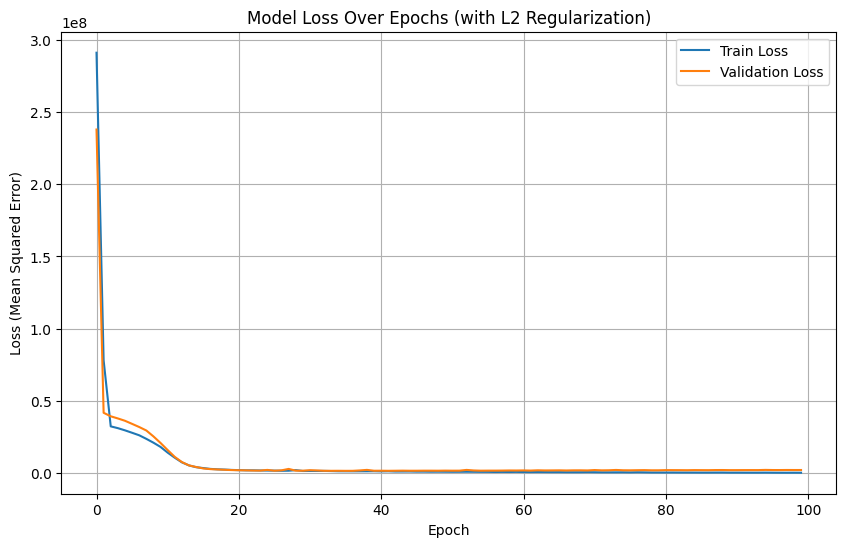

In [ ]:
import matplotlib.pyplot as plt

# Plot training & validation loss values
plt.figure(figsize=(10, 6))
plt.plot(results.history['loss'], label='Train Loss')
plt.plot(results.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs (with L2 Regularization)')
plt.ylabel('Loss (Mean Squared Error)')
plt.xlabel('Epoch')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import r2_score

# Make predictions on the scaled test set
y_pred = model.predict(X_test_scaled)

# Calculate the R2 score
r2 = r2_score(y_test, y_pred)

print(f"R2 Score on the test set (with L2 regularization): {r2:.4f}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
R2 Score on the test set (with L2 regularization): 0.9499


In [ ]:
import numpy as np

# Ensure predictions are in the correct shape (flat array for Series)
y_pred_flat = y_pred.flatten()

# Get the original IDs corresponding to the test set
# Since y_test preserves the original index, we can use it to get 'id' from df_original
test_ids = df_original.loc[y_test.index, 'id']

# Create the submission DataFrame
submission_df = pd.DataFrame({
    'id': test_ids,
    'target': y_pred_flat
})

# Display the first few rows of the submission file
display(submission_df.head())

# Save the submission file to a CSV
submission_df.to_csv('submission.csv', index=False)

print("Submission file 'submission.csv' created successfully!")

,id,target
1116,id_1116,21782.593750
1368,id_1368,10124.608398
422,id_422,21050.871094
413,id_413,7079.084961
451,id_451,18185.107422


Submission file 'submission.csv' created successfully!


In [ ]:
# Load the test dataset
df_test = pd.read_csv('/content/test.csv')

# Apply one-hot encoding to the test data, ensuring consistency with training data
# We need to re-create df_processed to get the correct column set for the original df (which contains test_ids)
# First, combine train and test for consistent one-hot encoding columns, then split again.

# Get columns used for one-hot encoding in training data
ohe_cols = ['location_type', 'land_use', 'zoning_code']

# Create a combined DataFrame for consistent one-hot encoding
# This ensures that both train and test sets have the same dummy variables, even if a category is missing in one.
combined_df = pd.concat([df_original.drop('target', axis=1), df_test], ignore_index=True, sort=False)
combined_df_processed = pd.get_dummies(combined_df, columns=ohe_cols, prefix={'location_type': 'location', 'land_use': 'landuse', 'zoning_code': 'zoning'})

# Split back into processed train and test
df_processed_test = combined_df_processed.iloc[len(df_original):].copy()

# Store test IDs before dropping
test_ids = df_test['id']

# Drop the 'id' column from the processed test features
X_test_submission_unscaled = df_processed_test.drop('id', axis=1)

# Identify numerical columns to scale in the test set
# Use the same list of numerical columns identified from the training set
# Ensure all numerical columns are present in X_test_submission_unscaled
missing_cols_in_test = set(numerical_cols_to_scale) - set(X_test_submission_unscaled.columns)
if missing_cols_in_test:
    print(f"Warning: Missing numerical columns in test set: {missing_cols_in_test}. This might lead to errors if these are critical for scaling.")

# Scale the numerical columns in the test data using the *fitted* scaler
X_test_submission_scaled = X_test_submission_unscaled.copy()
X_test_submission_scaled[numerical_cols_to_scale] = scaler.transform(X_test_submission_unscaled[numerical_cols_to_scale])

# Make predictions on the scaled test data
y_test_pred = model.predict(X_test_submission_scaled)

# Flatten predictions to a 1D array
y_test_pred_flat = y_test_pred.flatten()

# Create the submission DataFrame
submission_df_test = pd.DataFrame({
    'id': test_ids,
    'target': y_test_pred_flat
})

# Display the first few rows of the submission file
display(submission_df_test.head())

# Save the submission file to a CSV
submission_df_test.to_csv('submission.csv', index=False)

print("Submission file 'submission.csv' for test.csv created successfully!")

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


,id,target
0,id_0,6657.586914
1,id_1,19015.332031
2,id_2,12699.581055
3,id_3,29467.099609
4,id_4,17094.761719


Submission file 'submission.csv' for test.csv created successfully!
